The goal of this notebook is to generate the atlas comparison plot for Figure 2.

In [1]:
import os 
from pathlib import Path

from dotenv import dotenv_values
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

plt.rcParams["pdf.fonttype"] = 42

In [ ]:
# Setting up filepaths from config
CONFIG = dotenv_values("config.env") 
DATADIR = Path(CONFIG['DATADIR'])

OUTDIR = DATADIR / "publication" / "Fig_02"
os.makedirs(OUTDIR, exist_ok=True)

In [4]:
df_long = pd.read_csv(OUTDIR / "region_and_cluster_comparison_long_df_for_plot.csv",)

### Let's plot

In [5]:
bar_grid_width = 0.05
between_atlas_grid_width = 0.08
between_analyses_grid_width = 0.01

level_fontsize = 16
counts_fontsize = 16
analysis_fontsize = 16
atlas_fontsize = 16
ylabel_fontsize = 14
yticklabel_fontsize= 14

color_map = {
    'no cluster match': 'lightgrey',
    '1:1': '#990086',
    'many:1': '#4c0043',
    'matching cluster has no prediction': '#000000',
    'no overlap': '#f6392c',
    'partial overlap': '#ffd248',
    'full overlap': '#109b61',
    "match violates hierarchy": "pink"
}

/tmp/ipykernel_3181882/3482346573.py:171: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.95, 0.95])


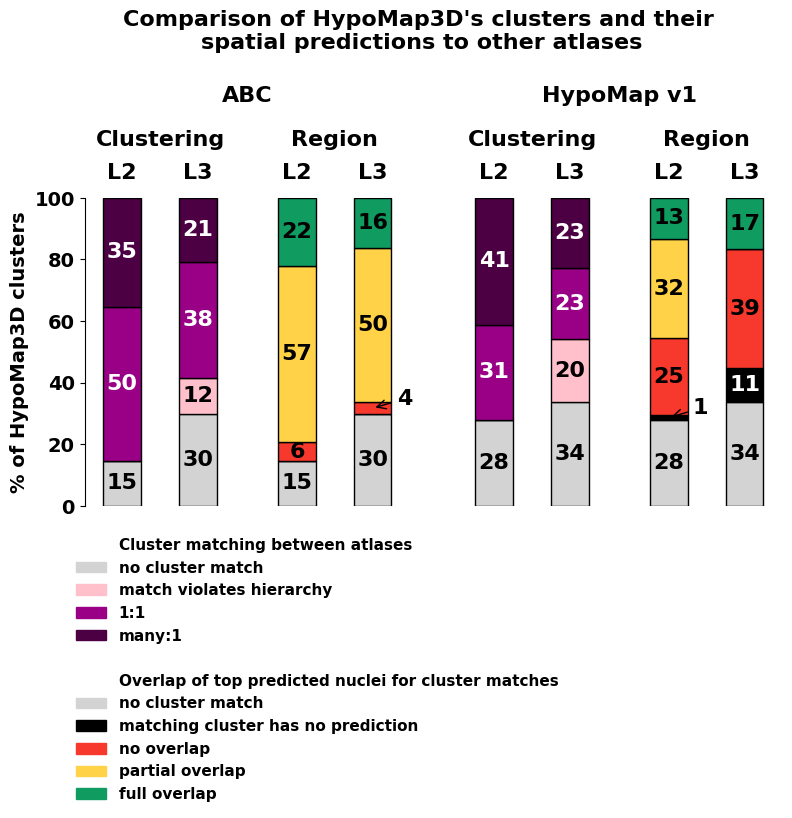

In [6]:

# --- Setup input data ---
subset = df_long[df_long['analysis'].isin([
    'cluster_mapping_category',
    'spatial_top_nuclei_match_category'
])].copy()

subset['level'] = subset['level'].astype(str)
subset['group'] = subset['atlas'] + ' | ' + subset['level'] + ' | ' + subset['analysis']

bar_order = [
    'abc | L2 | cluster_mapping_category',
    'abc | L3 | cluster_mapping_category',
    'abc | L2 | spatial_top_nuclei_match_category',
    'abc | L3 | spatial_top_nuclei_match_category',
    'hmv1 | L2 | cluster_mapping_category',
    'hmv1 | L3 | cluster_mapping_category',
    'hmv1 | L2 | spatial_top_nuclei_match_category',
    'hmv1 | L3 | spatial_top_nuclei_match_category',
]

stack_order_map = {
    'cluster_mapping_category': ['no cluster match', "match violates hierarchy", 
                            '1:1', 'many:1'],
    'spatial_top_nuclei_match_category': ['no cluster match', "matching cluster has no prediction", 'no overlap', 'partial overlap', 'full overlap'],
}

value_counts = (
    subset.groupby(['group', 'value'])
    .size()
    .reset_index(name='count')
)
value_counts['proportion'] = value_counts.groupby('group')['count'].transform(lambda x: x / x.sum())

group_data = {
    group: group_df.set_index('value')['proportion'].to_dict()
    for group, group_df in value_counts.groupby('group')
}

# --- Create Plot ---
fig = plt.figure(figsize=(9, 4))

bar_grid_width = 1
between_analyses_grid_width = 0.3
between_atlas_grid_width = 0.6
widths = [
    bar_grid_width, bar_grid_width, between_analyses_grid_width, bar_grid_width, bar_grid_width,
    between_atlas_grid_width,
    bar_grid_width, bar_grid_width, between_analyses_grid_width, bar_grid_width, bar_grid_width
]

gs = gridspec.GridSpec(1, len(widths), width_ratios=widths, wspace=0.01)
bar_positions = [0, 1, 3, 4, 6, 7, 9, 10]
axes = []

for i, (group, pos) in enumerate(zip(bar_order, bar_positions)):
    share_ax = axes[0] if i > 0 else None
    ax = fig.add_subplot(gs[0, pos], sharey=share_ax)
    axes.append(ax)

    stack_order = stack_order_map['cluster_mapping_category'] if 'cluster_mapping' in group else stack_order_map['spatial_top_nuclei_match_category']
    proportions = group_data.get(group, {})
    group_counts = value_counts[value_counts['group'] == group].set_index('value')['count'].to_dict()

    bottom = 0
    for cat in stack_order:
        height = proportions.get(cat, 0)
        color = color_map.get(cat, 'gray')
        ax.bar(0, height * 100, bottom=bottom * 100, color=color, edgecolor='black', width=1)

        percentage_label = f"{height * 100:.0f}"
        bar_center = (bottom + height / 2) * 100

        if height * 100 > 5:  # inside bar
            text_color = 'white' if cat in ['matching cluster has no prediction', '1:1', "many:1"] else 'black'
            ax.text(
                0, bar_center,
                percentage_label, 
                ha='center', va='center',
                color=text_color,
                fontsize=counts_fontsize, fontweight='bold'
            )
        elif height > 0:  # very small bar, annotate outside
            ax.annotate(
                percentage_label,
                xy=(0, bar_center),  # point to this
                xytext=(0.64, bar_center+3),  # position text to the right
                ha='left', va='center',
                fontsize=counts_fontsize, fontweight='bold',
                arrowprops=dict(arrowstyle='->', color='black', lw=1),
            )

        bottom += height


    ax.set_xticks([])
    ax.set_xticklabels([])


    for spine_name, spine in ax.spines.items():
        if i == 0 and spine_name == 'left':
            spine.set_visible(True)
        else:
            spine.set_visible(False)

    ax.set_xlim(-1, 1)
    ax.set_ylim(0, 100)

    if i == 0:
        ax.set_ylabel("% of HypoMap3D clusters", fontsize=ylabel_fontsize, fontweight='bold')
        for label in ax.get_yticklabels():
            label.set_fontweight('bold')
            label.set_fontsize(yticklabel_fontsize)
    else:
        ax.tick_params(left=False, labelleft=False)

    level = group.split(' | ')[1]
    ax.text(0, 1.05 * 100, level, ha='center', va='bottom', fontsize=level_fontsize, fontweight='bold')

# Dummy subplot to hold space between atlas groups
fig.add_subplot(gs[0, 5]).axis('off')

# Analysis section headers
fig.text((gs[0, 0].get_position(fig).x1 + gs[0, 1].get_position(fig).x0)/2, 1.01, "Clustering", fontsize=analysis_fontsize, fontweight='bold', ha='center')
fig.text((gs[0, 3].get_position(fig).x1 + gs[0, 4].get_position(fig).x0)/2, 1.01, "Region", fontsize=analysis_fontsize, fontweight='bold', ha='center')
fig.text((gs[0, 6].get_position(fig).x1 + gs[0, 7].get_position(fig).x0)/2, 1.01, "Clustering", fontsize=analysis_fontsize, fontweight='bold', ha='center')
fig.text((gs[0, 9].get_position(fig).x1 + gs[0, 10].get_position(fig).x0)/2, 1.01, "Region", fontsize=analysis_fontsize, fontweight='bold', ha='center')

# Atlas group headers
fig.text((gs[0, 1].get_position(fig).x1 + gs[0, 3].get_position(fig).x0)/2, 1.12, "ABC", fontsize=atlas_fontsize, fontweight='bold', ha='center')
fig.text((gs[0, 7].get_position(fig).x1 + gs[0, 9].get_position(fig).x0)/2, 1.12, "HypoMap v1", fontsize=atlas_fontsize, fontweight='bold', ha='center')

# Legend setup
legend_order = [
    'Cluster matching between atlases',
    'no cluster match',  
    "match violates hierarchy", 
    '1:1', 'many:1',
    '',
    'Overlap of top predicted nuclei for cluster matches',
    'no cluster match', 'matching cluster has no prediction', 'no overlap', 'partial overlap', 'full overlap'
]

handles, labels = [], []
for cat in legend_order:
    if cat == '' or 'Cluster' in cat or 'Overlap' in cat:
        handles.append(plt.Rectangle((0, 0), 0, 0, alpha=0.0))
        labels.append(cat)
    else:
        handles.append(plt.Rectangle((0, 0), 1, 1, color=color_map.get(cat, 'gray')))
        labels.append(cat)

legend = fig.legend(
    handles,
    labels,
    loc='center left',
    bbox_to_anchor=(0.1, -0.3),
    fontsize=11,
    frameon=False
)

for text in legend.get_texts():
    text.set_fontweight('bold')

fig.suptitle(
    "Comparison of HypoMap3D's clusters and their \nspatial predictions to other atlases",
    fontsize=16,
    fontweight='bold',
    y=1.35
)

plt.tight_layout(rect=[0, 0, 0.95, 0.95])
plt.savefig(OUTDIR / "cluster_and_spatial_comparison.pdf",bbox_inches='tight')
plt.show()
